# 20235166 박서준 3주차 과제

### 프롬프트1에 대한 생성형 AI의 답변 결과
- 과소적합(Underfitting) - degree = 1
  - 모델이 너무 단순해서 데이터의 실제 패턴(비선형 관계)을 충분히 표현하지 못하는 상태
  - *Train MSE*와 *Test MSE*가 둘 다 높게 나오는 것이 특징 (모델 자체가 데이터를 못 맞춤)
  - 이 실험에서 degree=1(직선)은 데이터가 곡선 형태라면 애초에 학습 데이터조차 잘 못 맞출 가능성이 큼
- 적절한 적합 - degree = 3
  - 모델의 복잡도가 데이터의 실제 패턴과 비슷한 수준
  - *Train MSE*도 적당히 낮고, *Test MSE*도 *Train MSE*와 크게 차이 나지 않음.
  - 데이터의 "진짜 규칙"을 학습했다고 볼 수 있는 지점
- 과적합(Overfitting) - degree = 15
  - 모델이 지나치게 복잡해서, 데이터의 실제 패턴뿐 아니라 학습 데이터에만 존재하는 Noise까지 암기한 상태
  - 그 결과 *Train MSE*는 매우 작아짐 - 학습 데이터 점들을 거의 완벽하게 지나가는 곡선을 그릴 수 있기 때문
  - 하지만 *Test MSE*는 오히려 커짐 - 노이즈까지 학습한 곡선은 새로운 데이터(테스트 셋)에서는 엉뚱하게 흔들리기 때문
- `Train MSE : degree 1 > degree 3 > degree 15 (계속 감소)`
- `Test MSE : degree 1 > degree 3 < degree 15 (U자 형태, degree 3 근처에서 최소`

- 일반화(Generalization)와의 연결
> 일반화 성능 = 모델이 학습에 쓰이지 않은 새로운 데이터에 대해서도 얼마나 잘 예측하는가
  - degree = 15는 Train 성능은 좋지만 일반화 성능은 나쁜 전형적인 사례
  - 즉 "학습 데이터를 잘 맞추는 것"과 "일반화를 잘하는 것"은 다른 문제이며, 목표는 항상 Test(또는 검증) 성능 기준의 일반화임
  - *Train MSE*만 보고 모델을 선택하면 항상 가장 복잡한 모델(degree↑)이 유리해 보이는 함정에 빠지므로, 반드시 *Test MSE*(또는 별도 validation set)를 기준으로 모델 복잡도를 선택해야 함.
  - "MSE가 낮다"만 보고 과소/과적합을 판단하면 안됨 - 반드시 Train과 Test를 같이 비교해야 구분 가능
  - 과소적합 = bias(편향)가 큰 문제, 과적합 = variance(분산)가 큰 문제 -> 이게 흔히 말하는 bias-variance tradeoff의 핵심


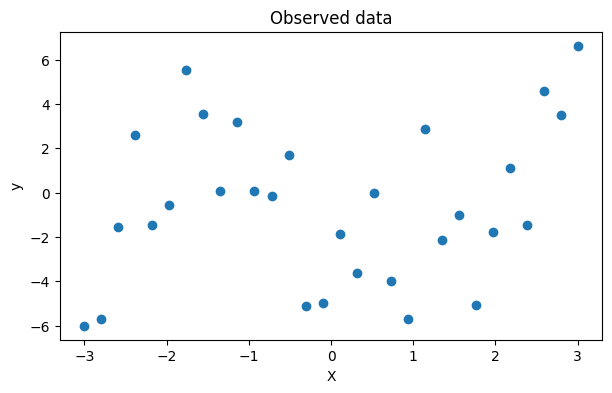

Train data :  21
Test data :  9


In [19]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

# 실험용 데이터 만들기
np.random.seed(42)

X = np.linspace(-3, 3, 30)
y = 0.5 * X**3 - 2 * X + np.random.normal(0, 3, 30)

plt.figure(figsize=(7, 4))
plt.scatter(X, y)
plt.xlabel("X")
plt.ylabel("y")
plt.title("Observed data")
plt.show()

# 훈련 데이터와 테스트 데이터로 나누기
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size = 0.3, # train data = 30%
    random_state = 42
)

print("Train data : ", len(X_train))
print("Test data : ", len(X_test))

### 프롬프트2에 대한 생성형 AI의 답변 결과 및 코드
#### 과적합 확인을 위한 추가 실험 제안
- 1순위 - 가장 직접적인 증거
  - Degree별 Train / Test MSE 곡선 (더 촘촘하게)
    - degree를 1, 3, 15만 볼 게 아니라 1 ~ 15(또는 그 이상)까지 1씩 증가시키며 전부 측정
    - 목적 : Train MSE는 단조 감소, Test MSE는 어느 지점부터 다시 증가하는 U자 곡선이 나오는지 확인 -> 이 "꺾이는 지점"이 바로 적정 복잡도


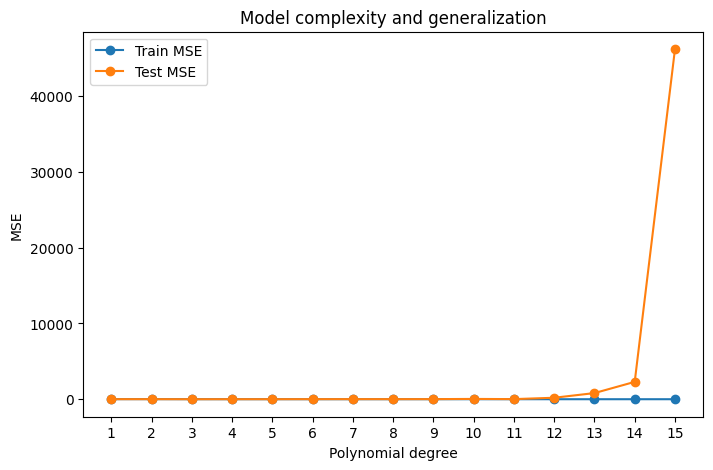

In [20]:
degrees = range(1, 16)
train_mse_list = []
test_mse_list = []

for i in degrees:
    model = make_pipeline(
        PolynomialFeatures(i),
        LinearRegression()
    )
    model.fit(X_train.reshape(-1, 1), y_train)

    train_pred = model.predict(X_train.reshape(-1, 1))
    test_pred = model.predict(X_test.reshape(-1, 1))

    train_mse_list.append(mean_squared_error(y_train, train_pred))
    test_mse_list.append(mean_squared_error(y_test, test_pred))

plt.figure(figsize=(8, 5))
plt.plot(degrees, train_mse_list, marker="o", label="Train MSE")
plt.plot(degrees, test_mse_list, marker="o", label="Test MSE")
plt.xlabel("Polynomial degree")
plt.ylabel("MSE")
plt.title("Model complexity and generalization")
plt.xticks(list(degrees))
plt.legend()
plt.show()

- 회귀 곡선 시각화 (Overfitting을 눈으로 확인)
  - degree = 1, 3, 15로 학습한 곡선을 실제 데이터 산점도 위에 겹쳐 그리기
  - 목적 : degree = 15 곡선이 데이터 점들 사이에서 비정상적으로 심하게 요동치는지 확인 -> 수치가 아니라 시각적으로도 과적합을 보여줄 수 있음
  

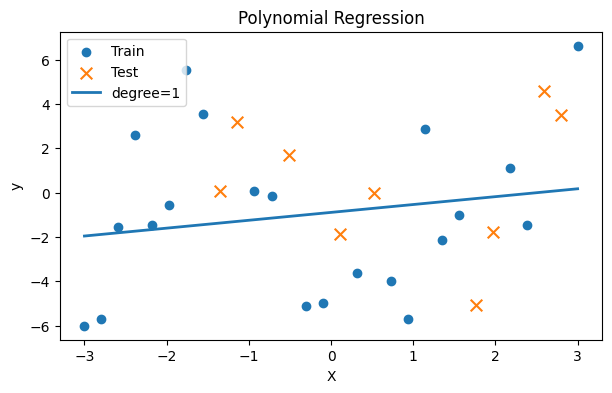

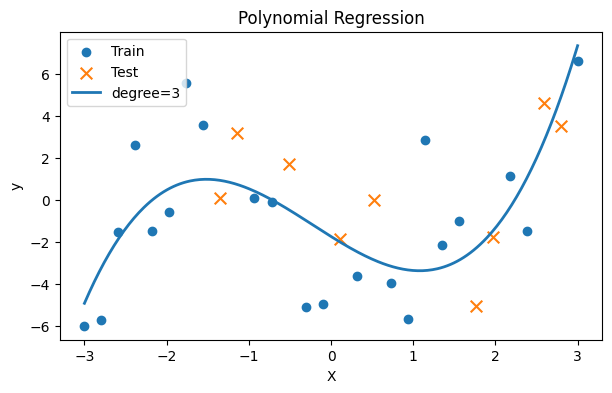

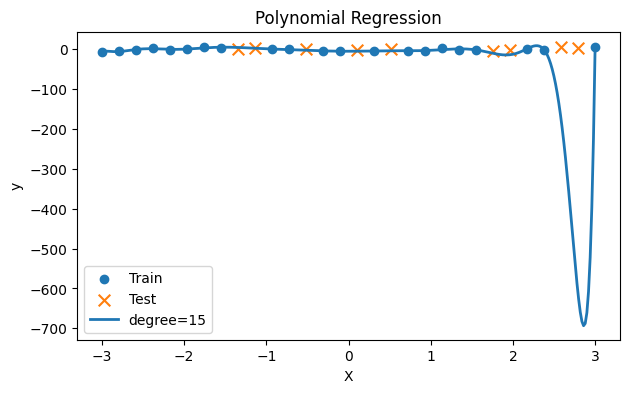

In [21]:
# 다항회귀 모델 학습
degrees = [1, 3, 15]

for i in degrees:
  model = make_pipeline(
      PolynomialFeatures(i),
      LinearRegression()
  )

  model.fit(X_train.reshape(-1, 1), y_train)

  # 학습된 모델을 그림으로 확인
  X_grid = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)
  y_grid = model.predict(X_grid)

  plt.figure(figsize=(7,4))
  plt.scatter(X_train, y_train, label="Train")
  plt.scatter(X_test, y_test, marker="x", s=70, label="Test")
  plt.plot(X_grid, y_grid, linewidth=2, label=f"degree={i}")
  plt.xlabel("X")
  plt.ylabel("y")
  plt.title("Polynomial Regression")
  plt.legend()
  plt.show()

- 2순위 - 원인(분산이 크다는 것)을 확인하는 실험
  - 다른 Random seed / 다른 train-test split으로 반복 실험
    - 데이터 분할(또는 노이즈)을 바꿔가며 degree = 15모델을 여러번 학습
    - 목적 : 과적합 모델은 데이터가 조금만 바뀌어도 곡선(계수)이 크게 달라짐 - 이게 높은 분산 특성. degree = 3은 상태적으로 안정적일 것

seed :  10


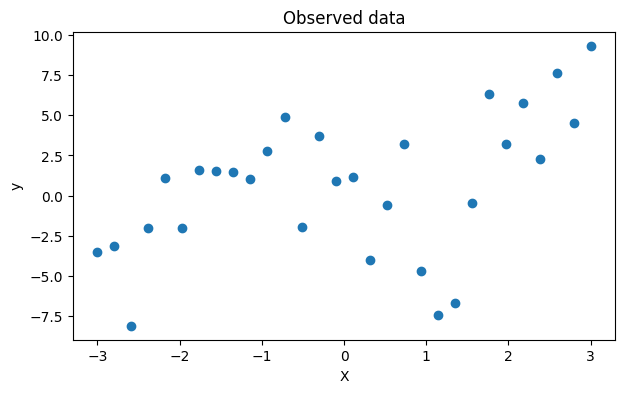

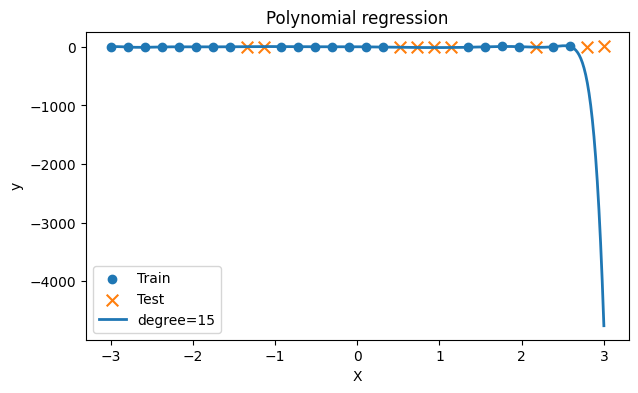

seed :  25


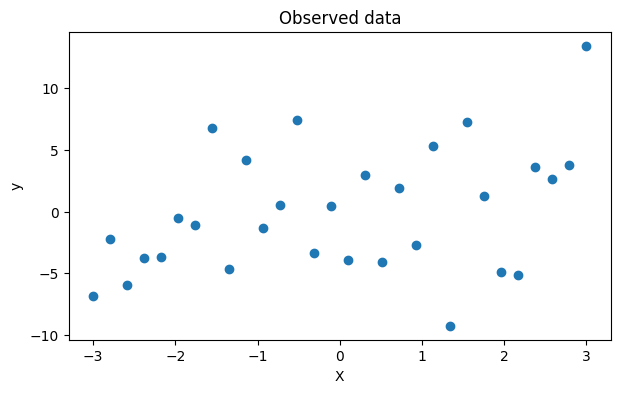

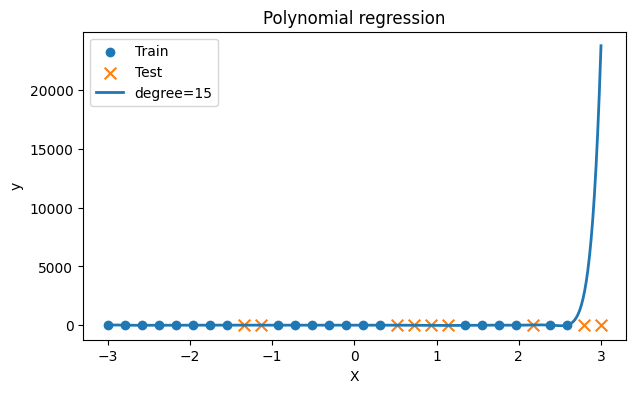

seed :  50


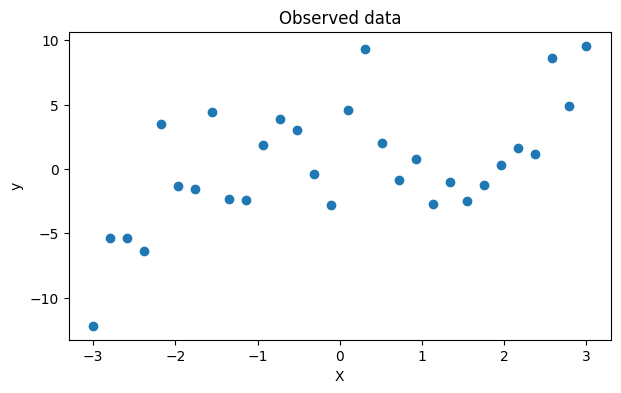

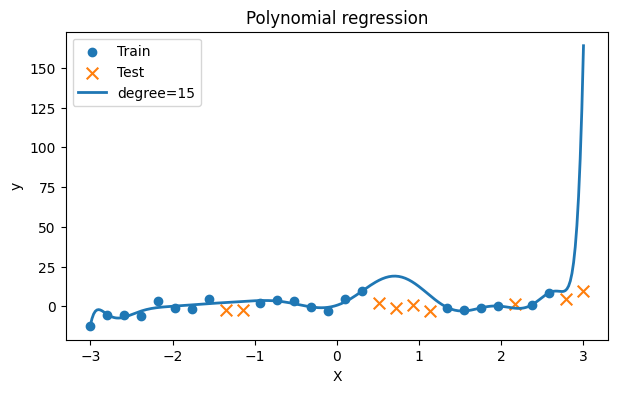

In [40]:
def make_data(s):
  print("seed : ", s)
  np.random.seed(s)

  X = np.linspace(-3, 3, 30)
  y = 0.5 * X**3 - 2 * X + np.random.normal(0, 3, 30)

  plt.figure(figsize=(7, 4))
  plt.scatter(X, y)
  plt.xlabel("X")
  plt.ylabel("y")
  plt.title("Observed data")
  plt.show()

  # 훈련 데이터와 테스트 데이터로 나누기
  X_train, X_test, y_train, y_test = train_test_split(
      X, y,
      test_size = 0.3, # train data = 30%
      random_state = 50
  )

  degree = 15

  model = make_pipeline(
      PolynomialFeatures(degree),
      LinearRegression()
  )

  model.fit(X_train.reshape(-1, 1), y_train)

  X_grid = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)
  y_grid = model.predict(X_grid)

  plt.figure(figsize=(7, 4))
  plt.scatter(X_train, y_train, label="Train")
  plt.scatter(X_test, y_test, marker="x", s=70, label="Test")
  plt.plot(X_grid, y_grid, linewidth=2, label=f"degree={degree}")
  plt.xlabel("X")
  plt.ylabel("y")
  plt.title("Polynomial regression")
  plt.legend()
  plt.show()
  print("===========================================================================")

random_seeds = [10, 25, 50]

for r in random_seeds:
  make_data(r)

- 3순위 - 해결책으로 검증(간접 증거)
  - 학습 곡선 (Learning Curve)
    - 학습 데이터 크기를 점점 늘려가며(예: 10%, 30%, 50%, 100%) degree = 15의 Train/Test MSE 변화 관찰
    - 목적 : 데이터가 많아질수록 과적합이 완화되는 경향(Test MSE 하락)이 보이면, "복잡한 모델 + 적은 데이터"가 원인이었음을 뒷받침
    

In [49]:
# 학습 데이터 크기 변경
def change_learning_data_size(s):
  print("학습 데이터 크기 : ", s)
  X_train, X_test, y_train, y_test = train_test_split(
      X, y,
      test_size=s,
      random_state=42
  )

  print("훈련 데이터 개수:", len(X_train))
  print("테스트 데이터 개수:", len(X_test))

  # degree = 15 모델 학습
  degree = 15

  model = make_pipeline(
      PolynomialFeatures(degree),
      LinearRegression()
  )

  model.fit(X_train.reshape(-1, 1), y_train)

  # Train / Test MSE 출력
  train_pred = model.predict(X_train.reshape(-1, 1))
  test_pred = model.predict(X_test.reshape(-1, 1))

  train_mse = mean_squared_error(y_train, train_pred)
  test_mse = mean_squared_error(y_test, test_pred)

  print(f"degree = {degree}")
  print(f"Train MSE = {train_mse:.3f}")
  print(f"Test  MSE = {test_mse:.3f}")
  print("====================")

data_sizes = [0.1, 0.3, 0.5, 0.9]

for d in data_sizes:
  change_learning_data_size(d)

학습 데이터 크기 :  0.1
훈련 데이터 개수: 27
테스트 데이터 개수: 3
degree = 15
Train MSE = 5.197
Test  MSE = 28.144
학습 데이터 크기 :  0.3
훈련 데이터 개수: 21
테스트 데이터 개수: 9
degree = 15
Train MSE = 4.022
Test  MSE = 35656.002
학습 데이터 크기 :  0.5
훈련 데이터 개수: 15
테스트 데이터 개수: 15
degree = 15
Train MSE = 0.000
Test  MSE = 2858003.884
학습 데이터 크기 :  0.9
훈련 데이터 개수: 3
테스트 데이터 개수: 27
degree = 15
Train MSE = 0.000
Test  MSE = 556387122206.383
